# Actividad 1. Modelado predictivo de actividad hemolítica mediante aprendizaje automático

# Samuel Salazar Diaz

## Parte 3: Construcción, evaluación e interpretación de modelos de machine learning

**Entrada:** salidas de la Parte 2 en `Act1_PSU/descriptores/` (`HemoPI-X_train_descriptores.csv` y `HemoPI-X_validation_descriptores.csv`). Los descriptores usados son los que **sobrevivieron** a la limpieza de la Parte 2 en cada dataset, y se leen de las columnas de cada CSV (no se fija una lista).

**Modelos (3):** regresión logística, Random Forest y XGBoost. Se entrenan por separado en HemoPI-1, HemoPI-2 y HemoPI-3 (9 modelos finales).

**Flujo para cada dataset y modelo:**
1. `Pipeline` = (escalado, solo para regresión logística) → **selección de variables** → clasificador. Todo dentro del pipeline, de modo que la selección y el escalado se ajustan solo con los datos de entrenamiento de cada pliegue (sin fuga de información).
2. **Validación cruzada estratificada de 5 pliegues** con `GridSearchCV` para ajustar hiperparámetros y el número de descriptores a conservar. Criterio de refit: AUC-ROC.
3. **Selección de variables:** RFE (eliminación recursiva) para regresión logística; selección por importancia (`SelectFromModel`) para Random Forest y XGBoost.
4. Evaluación en tres niveles: entrenamiento, validación cruzada y **validación externa** (el 20 % reservado).
5. Retención del modelo final, de los descriptores seleccionados y de sus pesos o importancias.

**Etiquetas:** `label = 1` corresponde a los archivos `class1` y `label = 0` a `class0`. En el artículo, HemoPI-1 distingue péptidos hemolíticos de no hemolíticos, mientras que HemoPI-2 y HemoPI-3 se usan para predecir potencia hemolítica alta o baja (Plisson et al., 2020).

## 1. Preparación del entorno

In [1]:
!pip -q install xgboost

In [2]:
import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             matthews_corrcoef, cohen_kappa_score, make_scorer, confusion_matrix,
                             roc_curve)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

In [3]:
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = '/content/drive/MyDrive/Act1_PSU'
DESC_DIR = f'{BASE_DIR}/descriptores'             # salida de la Parte 2
RES_DIR  = f'{BASE_DIR}/resultados_modelos'       # salida de esta Parte 3
MOD_DIR  = f'{RES_DIR}/modelos'
FIG_DIR  = f'{RES_DIR}/figuras'
TAB_DIR  = f'{RES_DIR}/tablas'
for d in (MOD_DIR, FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)

DATASETS = ['HemoPI-1', 'HemoPI-2', 'HemoPI-3']
MODELOS  = ['Regresión logística', 'Random Forest', 'XGBoost']
SLUG = {'Regresión logística': 'reg_logistica', 'Random Forest': 'random_forest', 'XGBoost': 'xgboost'}
COLOR = {'Regresión logística': '#4C72B0', 'Random Forest': '#55A868', 'XGBoost': '#DD8452'}

SEED = 42
N_FOLDS = 5
RECALCULAR = False   # True: vuelve a entrenar aunque exista el GridSearchCV guardado en Drive
                     # (si cambias parrillas o datos, ponlo en True o borra la carpeta 'modelos')

Mounted at /content/drive


## 2. Carga de los datos de la Parte 2

Cada CSV contiene `peptide_id`, `sequence`, `smiles`, `label` y los descriptores seleccionados. Se separan las columnas de identificación de las de descriptores y se comprueba que entrenamiento y validación tengan **exactamente las mismas columnas**.

In [4]:
META_COLS = ['peptide_id', 'sequence', 'smiles', 'label']

datos = {}
for ds in DATASETS:
    tr = pd.read_csv(f'{DESC_DIR}/{ds}_train_descriptores.csv')
    va = pd.read_csv(f'{DESC_DIR}/{ds}_validation_descriptores.csv')
    cols = [c for c in tr.columns if c not in META_COLS]
    assert cols == [c for c in va.columns if c not in META_COLS], f'{ds}: columnas distintas en train y validación'
    datos[ds] = {'X_tr': tr[cols], 'y_tr': tr['label'].astype(int).values,
                 'X_va': va[cols], 'y_va': va['label'].astype(int).values, 'cols': cols}

resumen = pd.DataFrame({
    ds: {'n_entrenamiento': len(d['y_tr']), 'n_validacion': len(d['y_va']), 'n_descriptores': len(d['cols']),
         '% clase 1 (entrenamiento)': round(d['y_tr'].mean() * 100, 1),
         '% clase 1 (validación)': round(d['y_va'].mean() * 100, 1)}
    for ds, d in datos.items()}).T
resumen

,n_entrenamiento,n_validacion,n_descriptores,% clase 1 (entrenamiento),% clase 1 (validación)
HemoPI-1,884.0,220.0,16.0,50.0,50.0
HemoPI-2,812.0,202.0,17.0,54.4,54.5
HemoPI-3,1298.0,325.0,17.0,54.5,54.5


In [5]:
# Descriptores disponibles en cada dataset (los que sobrevivieron al filtro de la Parte 2)
for ds in DATASETS:
    print(f"{ds} ({len(datos[ds]['cols'])}):", ', '.join(datos[ds]['cols']))

HemoPI-1 (16): nAcid, nBase, nAromAtom, nS, BalabanJ, FCSP3, fragCpx, nHBAcc, nHBDon, FilterItLogS, PEOE_VSA6, nARing, SLogP, MW, AMW, WPath
HemoPI-2 (17): nAcid, nBase, nAromAtom, nS, BalabanJ, FCSP3, fragCpx, nHBAcc, nHBDon, FilterItLogS, PEOE_VSA6, SlogP_VSA5, nARing, SLogP, MW, AMW, WPath
HemoPI-3 (17): nAcid, nBase, nAromAtom, nS, BalabanJ, FCSP3, fragCpx, nHBAcc, nHBDon, FilterItLogS, PEOE_VSA6, SlogP_VSA5, nARing, SLogP, MW, AMW, WPath


## 3. Definición de los modelos y las parrillas de hiperparámetros

- **Regresión logística:** `StandardScaler` → **RFE** (con regresión logística como estimador interno) → regresión logística. Se ajustan el número de descriptores y la regularización `C` (L2).
- **Random Forest:** **selección por importancia** (`SelectFromModel` con un Random Forest, quedándose con los `k` descriptores más importantes) → Random Forest. Se ajustan `k`, número de árboles, profundidad máxima y tamaño mínimo de hoja.
- **XGBoost:** selección por importancia con XGBoost → XGBoost. Se ajustan `k`, número de árboles, profundidad y tasa de aprendizaje.

**Desbalance de clases:** se usa `class_weight='balanced'` en regresión logística y Random Forest, y `scale_pos_weight` (proporción negativos/positivos del entrenamiento) en XGBoost. Si las clases están equilibradas, el efecto es mínimo.

Las parrillas son pequeñas a propósito: con pocos datos, parrillas muy grandes sobreajustan a la validación cruzada. El número de descriptores a conservar (`k`) se elige por validación cruzada entre 6, 8, 10, 12 y todos.

In [6]:
def construir_modelo(nombre, n_desc, y_tr):
    """Devuelve (pipeline, parrilla) para el modelo pedido."""
    # Valores de k (descriptores a conservar) que se prueban; siempre incluye 'todos'
    ks = sorted({k for k in (6, 8, 10, 12) if k < n_desc} | {n_desc})
    # Proporción negativos/positivos, usada por XGBoost para compensar desbalance
    spw = float((y_tr == 0).sum() / max((y_tr == 1).sum(), 1))

    if nombre == 'Regresión logística':
        pipe = Pipeline([
            ('scaler', StandardScaler()),   # imprescindible para coeficientes comparables y para RFE
            ('sel', RFE(LogisticRegression(max_iter=5000, class_weight='balanced'), step=1)),
            ('clf', LogisticRegression(max_iter=5000, class_weight='balanced')),
        ])
        grid = {'sel__n_features_to_select': ks, 'clf__C': [0.01, 0.1, 1, 10]}

    elif nombre == 'Random Forest':
        pipe = Pipeline([
            ('sel', SelectFromModel(RandomForestClassifier(n_estimators=100, class_weight='balanced',
                                                           random_state=SEED, n_jobs=1),
                                    threshold=-np.inf)),   # threshold=-inf + max_features => los k más importantes
            ('clf', RandomForestClassifier(class_weight='balanced', random_state=SEED, n_jobs=1)),
        ])
        grid = {'sel__max_features': ks, 'clf__n_estimators': [200, 400],
                'clf__max_depth': [None, 8], 'clf__min_samples_leaf': [1, 3]}

    elif nombre == 'XGBoost':
        base = dict(scale_pos_weight=spw, eval_metric='logloss', random_state=SEED, n_jobs=1, tree_method='hist')
        pipe = Pipeline([
            ('sel', SelectFromModel(XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, **base),
                                    threshold=-np.inf)),
            ('clf', XGBClassifier(**base)),
        ])
        grid = {'sel__max_features': ks, 'clf__n_estimators': [100, 300],
                'clf__max_depth': [2, 3, 5], 'clf__learning_rate': [0.05, 0.1]}
    else:
        raise ValueError(nombre)
    return pipe, grid

# Métricas calculadas en cada pliegue de la validación cruzada (todas se registran; el refit usa AUC-ROC)
SCORERS = {
    'accuracy':    'accuracy',
    'precision':   make_scorer(precision_score, zero_division=0),
    'recall':      'recall',                                   # sensibilidad
    'specificity': make_scorer(recall_score, pos_label=0),     # especificidad
    'f1':          'f1',
    'roc_auc':     'roc_auc',
    'mcc':         make_scorer(matthews_corrcoef),
    'kappa':       make_scorer(cohen_kappa_score),
}
METRICAS = list(SCORERS.keys())

# Validación cruzada estratificada: mantiene la proporción de clases en cada pliegue
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

# Vista previa de las parrillas (con el primer dataset)
d0 = datos[DATASETS[0]]
for m in MODELOS:
    _, g = construir_modelo(m, len(d0['cols']), d0['y_tr'])
    n_comb = int(np.prod([len(v) for v in g.values()]))
    print(f'{m}: {n_comb} combinaciones x {N_FOLDS} pliegues |', {k: v for k, v in g.items()})

Regresión logística: 20 combinaciones x 5 pliegues | {'sel__n_features_to_select': [6, 8, 10, 12, 16], 'clf__C': [0.01, 0.1, 1, 10]}
Random Forest: 40 combinaciones x 5 pliegues | {'sel__max_features': [6, 8, 10, 12, 16], 'clf__n_estimators': [200, 400], 'clf__max_depth': [None, 8], 'clf__min_samples_leaf': [1, 3]}
XGBoost: 60 combinaciones x 5 pliegues | {'sel__max_features': [6, 8, 10, 12, 16], 'clf__n_estimators': [100, 300], 'clf__max_depth': [2, 3, 5], 'clf__learning_rate': [0.05, 0.1]}


## 4. Entrenamiento con validación cruzada y ajuste de hiperparámetros

Para cada dataset y modelo se ejecuta `GridSearchCV` sobre **solo el conjunto de entrenamiento**. El mejor pipeline (hiperparámetros + número de descriptores) se reajusta con todo el entrenamiento y es el **modelo final**. El objeto completo se guarda en Drive: si se corta la sesión, al volver a ejecutar se carga sin reentrenar.

In [7]:
gridsearch = {}   # (dataset, modelo) -> GridSearchCV ajustado

for ds in DATASETS:
    d = datos[ds]
    for mod in MODELOS:
        ruta = f'{MOD_DIR}/{ds}_{SLUG[mod]}_gridsearch.joblib'
        if os.path.exists(ruta) and not RECALCULAR:
            gs = joblib.load(ruta)
            estado = 'cargado'
        else:
            pipe, grid = construir_modelo(mod, len(d['cols']), d['y_tr'])
            gs = GridSearchCV(pipe, grid, scoring=SCORERS, refit='roc_auc', cv=cv,
                              n_jobs=-1, error_score='raise')
            gs.fit(d['X_tr'], d['y_tr'])
            joblib.dump(gs, ruta)
            estado = 'entrenado'
        gridsearch[(ds, mod)] = gs
        print(f'{ds} | {mod:<20} | {estado} | AUC CV = {gs.best_score_:.3f}')

HemoPI-1 | Regresión logística  | entrenado | AUC CV = 0.966
HemoPI-1 | Random Forest        | entrenado | AUC CV = 0.984
HemoPI-1 | XGBoost              | entrenado | AUC CV = 0.982
HemoPI-2 | Regresión logística  | entrenado | AUC CV = 0.760
HemoPI-2 | Random Forest        | entrenado | AUC CV = 0.834
HemoPI-2 | XGBoost              | entrenado | AUC CV = 0.834
HemoPI-3 | Regresión logística  | entrenado | AUC CV = 0.762
HemoPI-3 | Random Forest        | entrenado | AUC CV = 0.822
HemoPI-3 | XGBoost              | entrenado | AUC CV = 0.807


In [8]:
# Mejores hiperparámetros y número de descriptores conservados por cada modelo
filas = []
for (ds, mod), gs in gridsearch.items():
    sel = gs.best_estimator_.named_steps['sel']
    fila = {'dataset': ds, 'modelo': mod, 'AUC CV': round(gs.best_score_, 3),
            'n_desc_disponibles': len(datos[ds]['cols']), 'n_desc_seleccionados': int(sel.get_support().sum())}
    fila.update({k.split('__')[1]: v for k, v in gs.best_params_.items()})
    filas.append(fila)

mejores = pd.DataFrame(filas)
mejores.to_csv(f'{TAB_DIR}/mejores_hiperparametros.csv', index=False)
mejores

,dataset,modelo,AUC CV,n_desc_disponibles,n_desc_seleccionados,C,n_features_to_select,max_depth,min_samples_leaf,n_estimators,max_features,learning_rate
0,HemoPI-1,Regresión logística,0.966,16,16,10.0,16.0,NaN,NaN,NaN,NaN,NaN
1,HemoPI-1,Random Forest,0.984,16,16,NaN,NaN,NaN,1.0,200.0,16.0,NaN
2,HemoPI-1,XGBoost,0.982,16,10,NaN,NaN,5.0,NaN,100.0,10.0,0.10
3,HemoPI-2,Regresión logística,0.760,17,12,10.0,12.0,NaN,NaN,NaN,NaN,NaN
4,HemoPI-2,Random Forest,0.834,17,17,NaN,NaN,NaN,3.0,400.0,17.0,NaN
5,HemoPI-2,XGBoost,0.834,17,12,NaN,NaN,5.0,NaN,300.0,12.0,0.05
6,HemoPI-3,Regresión logística,0.762,17,17,10.0,17.0,NaN,NaN,NaN,NaN,NaN
7,HemoPI-3,Random Forest,0.822,17,17,NaN,NaN,NaN,1.0,200.0,17.0,NaN
8,HemoPI-3,XGBoost,0.807,17,12,NaN,NaN,5.0,NaN,100.0,12.0,0.10


## 5. Tabla comparativa de desempeño

Se reportan tres niveles para cada modelo:
- **Entrenamiento:** el modelo final evaluado sobre los mismos datos con que se entrenó (indica cuánto memoriza).
- **CV (5 pliegues):** media de las métricas de los pliegues de validación para la mejor combinación de hiperparámetros. Es el desempeño **interno**. Es ligeramente optimista porque los hiperparámetros se eligieron con esos mismos pliegues.
- **Validación externa:** el 20 % reservado, que no participó en ningún ajuste.

Las métricas de clase (accuracy, precision, recall, F1, MCC, kappa) usan el umbral 0,5. Además se reporta el intervalo de confianza del 95 % (*bootstrap*, 1000 remuestreos) del AUC y del MCC en validación externa.

In [9]:
def metricas(y, proba, umbral=0.5):
    """Métricas de clasificación binaria a partir de probabilidades de la clase 1."""
    pred = (proba >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'accuracy': accuracy_score(y, pred),
            'precision': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred),
            'specificity': tn / (tn + fp) if (tn + fp) else np.nan,
            'f1': f1_score(y, pred),
            'roc_auc': roc_auc_score(y, proba),
            'mcc': matthews_corrcoef(y, pred),
            'kappa': cohen_kappa_score(y, pred)}

def ic_bootstrap(y, proba, n_boot=1000, semilla=SEED):
    """IC 95 % (percentiles) de AUC y MCC por remuestreo bootstrap de la validación externa."""
    rng = np.random.default_rng(semilla)
    aucs, mccs = [], []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < 2:
            continue
        aucs.append(roc_auc_score(y[i], proba[i]))
        mccs.append(matthews_corrcoef(y[i], (proba[i] >= 0.5).astype(int)))
    return np.percentile(aucs, [2.5, 97.5]), np.percentile(mccs, [2.5, 97.5])

filas, filas_sd, probas_ext = [], [], {}
for (ds, mod), gs in gridsearch.items():
    d = datos[ds]
    mejor = gs.best_estimator_
    i = gs.best_index_

    # Nivel 1: entrenamiento (reajuste)
    p_tr = mejor.predict_proba(d['X_tr'])[:, 1]
    filas.append({'dataset': ds, 'modelo': mod, 'nivel': 'Entrenamiento', **metricas(d['y_tr'], p_tr)})

    # Nivel 2: validación cruzada (media y desviación de los 5 pliegues, mejor combinación)
    filas.append({'dataset': ds, 'modelo': mod, 'nivel': 'CV (5 pliegues)',
                  **{m: gs.cv_results_[f'mean_test_{m}'][i] for m in METRICAS}})
    filas_sd.append({'dataset': ds, 'modelo': mod,
                     **{m: gs.cv_results_[f'std_test_{m}'][i] for m in METRICAS}})

    # Nivel 3: validación externa (20 %)
    p_ext = mejor.predict_proba(d['X_va'])[:, 1]
    probas_ext[(ds, mod)] = p_ext
    ic_auc, ic_mcc = ic_bootstrap(d['y_va'], p_ext)
    filas.append({'dataset': ds, 'modelo': mod, 'nivel': 'Validación externa', **metricas(d['y_va'], p_ext),
                  'IC95 AUC': f'[{ic_auc[0]:.3f}, {ic_auc[1]:.3f}]', 'IC95 MCC': f'[{ic_mcc[0]:.3f}, {ic_mcc[1]:.3f}]'})

tabla = pd.DataFrame(filas)
tabla_sd = pd.DataFrame(filas_sd)
tabla.to_csv(f'{TAB_DIR}/metricas_todos_los_niveles.csv', index=False)
tabla_sd.to_csv(f'{TAB_DIR}/metricas_cv_desviaciones.csv', index=False)
print('Tabla guardada. Filas:', len(tabla))

Tabla guardada. Filas: 27


In [10]:
# Tabla comparativa de validación externa (una fila por dataset y modelo)
cols_m = METRICAS + ['IC95 AUC', 'IC95 MCC']
ext = (tabla[tabla['nivel'] == 'Validación externa']
       .set_index(['dataset', 'modelo'])[cols_m])
ext_fmt = ext.copy()
for c in METRICAS:
    ext_fmt[c] = ext_fmt[c].astype(float).round(3)
ext_fmt

accuracy  precision  recall  specificity     f1  \
dataset  modelo                                                                 
HemoPI-1 Regresión logística     0.882      0.889   0.873        0.891  0.881   
         Random Forest           0.936      0.962   0.909        0.964  0.935   
         XGBoost                 0.927      0.943   0.909        0.945  0.926   
HemoPI-2 Regresión logística     0.713      0.741   0.727        0.696  0.734   
         Random Forest           0.762      0.782   0.782        0.739  0.782   
         XGBoost                 0.757      0.770   0.791        0.717  0.780   
HemoPI-3 Regresión logística     0.729      0.754   0.746        0.709  0.750   
         Random Forest           0.794      0.789   0.847        0.730  0.817   
         XGBoost                 0.748      0.778   0.751        0.743  0.764   

                              roc_auc    mcc  kappa        IC95 AUC  \
dataset  modelo                                                       
HemoPI-1 Regresión logística    0.960  0.764  0.764  [0.936, 0.981]   
         Random Forest          0.989  0.874  0.873  [0.978, 0.997]   
         XGBoost                0.983  0.855  0.855  [0.967, 0.994]   
HemoPI-2 Regresión logística    0.764  0.422  0.422  [0.699, 0.833]   
         Random Forest          0.856  0.521  0.521  [0.796, 0.908]   
         XGBoost                0.830  0.510  0.510  [0.773, 0.885]   
HemoPI-3 Regresión logística    0.791  0.455  0.455  [0.741, 0.839]   
         Random Forest          0.859  0.583  0.581  [0.820, 0.898]   
         XGBoost                0.825  0.493  0.493  [0.779, 0.869]   

                                    IC95 MCC  
dataset  modelo                               
HemoPI-1 Regresión logística  [0.673, 0.846]  
         Random Forest        [0.811, 0.936]  
         XGBoost              [0.786, 0.919]  
HemoPI-2 Regresión logística  [0.307, 0.555]  
         Random Forest        [0.396, 0.644]  
         XGBoost              [0.389, 0.633]  
HemoPI-3 Regresión logística  [0.352, 0.551]  
         Random Forest        [0.497, 0.671]  
         XGBoost              [0.391, 0.587]

In [11]:
# Tabla de validación cruzada: media ± desviación estándar de los 5 pliegues
cv_m = tabla[tabla['nivel'] == 'CV (5 pliegues)'].set_index(['dataset', 'modelo'])[METRICAS]
cv_s = tabla_sd.set_index(['dataset', 'modelo'])[METRICAS]
cv_fmt = cv_m.round(3).astype(str) + ' ± ' + cv_s.round(3).astype(str)
cv_fmt

accuracy      precision         recall  \
dataset  modelo                                                             
HemoPI-1 Regresión logística  0.915 ± 0.027   0.912 ± 0.02  0.918 ± 0.037   
         Random Forest         0.93 ± 0.016  0.926 ± 0.023  0.934 ± 0.018   
         XGBoost              0.929 ± 0.017   0.926 ± 0.02  0.932 ± 0.019   
HemoPI-2 Regresión logística   0.706 ± 0.04  0.724 ± 0.034  0.744 ± 0.081   
         Random Forest        0.766 ± 0.023  0.781 ± 0.007  0.792 ± 0.054   
         XGBoost              0.765 ± 0.012  0.792 ± 0.032  0.774 ± 0.041   
HemoPI-3 Regresión logística  0.713 ± 0.021  0.744 ± 0.012  0.722 ± 0.049   
         Random Forest        0.742 ± 0.025  0.745 ± 0.024  0.802 ± 0.023   
         XGBoost              0.742 ± 0.016  0.763 ± 0.021  0.766 ± 0.032   

                                specificity             f1        roc_auc  \
dataset  modelo                                                             
HemoPI-1 Regresión logística  0.912 ± 0.018  0.915 ± 0.028  0.966 ± 0.017   
         Random Forest        0.925 ± 0.024   0.93 ± 0.016  0.984 ± 0.008   
         XGBoost              0.925 ± 0.021  0.929 ± 0.017  0.982 ± 0.009   
HemoPI-2 Regresión logística  0.659 ± 0.059  0.732 ± 0.045   0.76 ± 0.027   
         Random Forest        0.735 ± 0.018  0.786 ± 0.029   0.834 ± 0.02   
         XGBoost              0.754 ± 0.055  0.781 ± 0.013  0.834 ± 0.023   
HemoPI-3 Regresión logística  0.702 ± 0.025  0.732 ± 0.027  0.762 ± 0.019   
         Random Forest        0.669 ± 0.036  0.772 ± 0.021  0.822 ± 0.021   
         XGBoost              0.714 ± 0.038  0.764 ± 0.016  0.807 ± 0.015   

                                        mcc          kappa  
dataset  modelo                                             
HemoPI-1 Regresión logística  0.831 ± 0.054   0.83 ± 0.054  
         Random Forest         0.86 ± 0.032   0.86 ± 0.032  
         XGBoost              0.858 ± 0.034  0.857 ± 0.034  
HemoPI-2 Regresión logística   0.409 ± 0.08  0.405 ± 0.077  
         Random Forest         0.53 ± 0.044  0.528 ± 0.044  
         XGBoost              0.529 ± 0.027  0.527 ± 0.025  
HemoPI-3 Regresión logística  0.424 ± 0.039  0.422 ± 0.039  
         Random Forest         0.477 ± 0.05  0.475 ± 0.051  
         XGBoost               0.48 ± 0.033  0.479 ± 0.033

In [12]:
# Comparación del desempeño interno (CV) con la validación externa y el entrenamiento
# delta = externa - CV (valores muy negativos sugieren sobreajuste o diferencias entre particiones)
comp = []
for (ds, mod) in gridsearch:
    sub = tabla[(tabla['dataset'] == ds) & (tabla['modelo'] == mod)].set_index('nivel')
    for m in ['accuracy', 'roc_auc', 'mcc', 'f1']:
        comp.append({'dataset': ds, 'modelo': mod, 'metrica': m,
                     'Entrenamiento': sub.loc['Entrenamiento', m], 'CV': sub.loc['CV (5 pliegues)', m],
                     'Externa': sub.loc['Validación externa', m]})
comp = pd.DataFrame(comp)
comp['delta (externa - CV)'] = comp['Externa'] - comp['CV']
comp['brecha (entren. - externa)'] = comp['Entrenamiento'] - comp['Externa']
comp = comp.round(3)
comp.to_csv(f'{TAB_DIR}/comparacion_interno_externo.csv', index=False)
comp.pivot_table(index=['dataset', 'modelo'], columns='metrica',
                 values=['Entrenamiento', 'CV', 'Externa', 'delta (externa - CV)'])

CV                       Entrenamiento  \
metrica                      accuracy     f1    mcc roc_auc      accuracy   
dataset  modelo                                                             
HemoPI-1 Random Forest          0.930  0.930  0.860   0.984         1.000   
         Regresión logística    0.915  0.915  0.831   0.966         0.921   
         XGBoost                0.929  0.929  0.858   0.982         0.999   
HemoPI-2 Random Forest          0.766  0.786  0.530   0.834         0.959   
         Regresión logística    0.706  0.732  0.409   0.760         0.714   
         XGBoost                0.765  0.781  0.529   0.834         0.978   
HemoPI-3 Random Forest          0.742  0.772  0.477   0.822         1.000   
         Regresión logística    0.713  0.732  0.424   0.762         0.723   
         XGBoost                0.742  0.764  0.480   0.807         0.947   

                                                    Externa                \
metrica                          f1    mcc roc_auc accuracy     f1    mcc   
dataset  modelo                                                             
HemoPI-1 Random Forest        1.000  1.000   1.000    0.936  0.935  0.874   
         Regresión logística  0.921  0.842   0.975    0.882  0.881  0.764   
         XGBoost              0.999  0.998   1.000    0.927  0.926  0.855   
HemoPI-2 Random Forest        0.963  0.918   0.994    0.762  0.782  0.521   
         Regresión logística  0.739  0.423   0.780    0.713  0.734  0.422   
         XGBoost              0.980  0.955   0.998    0.757  0.780  0.510   
HemoPI-3 Random Forest        1.000  1.000   1.000    0.794  0.817  0.583   
         Regresión logística  0.743  0.444   0.783    0.729  0.750  0.455   
         XGBoost              0.951  0.893   0.986    0.748  0.764  0.493   

                                     delta (externa - CV)                \
metrica                      roc_auc             accuracy     f1    mcc   
dataset  modelo                                                           
HemoPI-1 Random Forest         0.989                0.006  0.004  0.014   
         Regresión logística   0.960               -0.033 -0.034 -0.067   
         XGBoost               0.983               -0.001 -0.003 -0.003   
HemoPI-2 Random Forest         0.856               -0.004 -0.004 -0.009   
         Regresión logística   0.764                0.007  0.002  0.013   
         XGBoost               0.830               -0.007 -0.001 -0.019   
HemoPI-3 Random Forest         0.859                0.052  0.045  0.106   
         Regresión logística   0.791                0.017  0.018  0.031   
         XGBoost               0.825                0.006  0.001  0.013   

                                      
metrica                      roc_auc  
dataset  modelo                       
HemoPI-1 Random Forest         0.004  
         Regresión logística  -0.006  
         XGBoost               0.001  
HemoPI-2 Random Forest         0.022  
         Regresión logística   0.004  
         XGBoost              -0.004  
HemoPI-3 Random Forest         0.037  
         Regresión logística   0.029  
         XGBoost               0.018

## 6. Curvas ROC

Sensibilidad frente a 1 – especificidad.
- **Fila superior (interna):** predicciones *out-of-fold* de la validación cruzada de 5 pliegues, con el modelo ya ajustado. Cada péptido se predice con un modelo que no lo vio.
- **Fila inferior (externa):** validación externa (20 %).

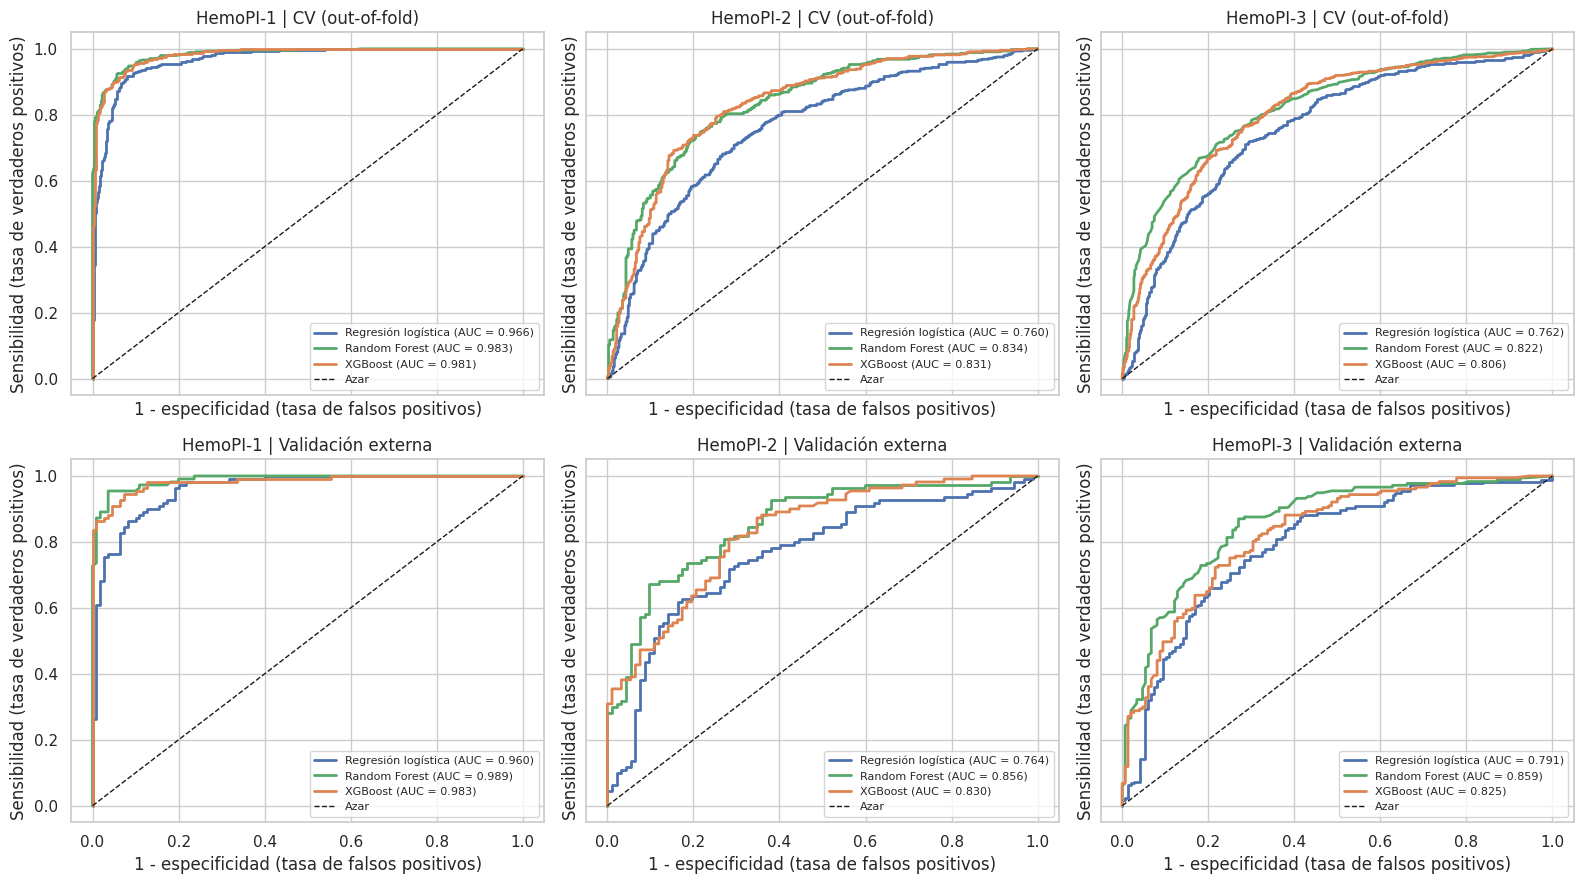

In [13]:
# Predicciones out-of-fold con el mejor pipeline (la selección y el escalado se rehacen dentro de cada pliegue)
probas_cv = {}
for (ds, mod), gs in gridsearch.items():
    d = datos[ds]
    probas_cv[(ds, mod)] = cross_val_predict(clone(gs.best_estimator_), d['X_tr'], d['y_tr'],
                                             cv=cv, method='predict_proba')[:, 1]

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)
for j, ds in enumerate(DATASETS):
    for fila, (probas, y, titulo) in enumerate([(probas_cv, datos[ds]['y_tr'], 'CV (out-of-fold)'),
                                                (probas_ext, datos[ds]['y_va'], 'Validación externa')]):
        ax = axes[fila, j]
        for mod in MODELOS:
            p = probas[(ds, mod)]
            fpr, tpr, _ = roc_curve(y, p)
            ax.plot(fpr, tpr, color=COLOR[mod], lw=2, label=f'{mod} (AUC = {roc_auc_score(y, p):.3f})')
        ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Azar')
        ax.set_title(f'{ds} | {titulo}')
        ax.set_xlabel('1 - especificidad (tasa de falsos positivos)')
        ax.set_ylabel('Sensibilidad (tasa de verdaderos positivos)')
        ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/curvas_roc.png', dpi=200, bbox_inches='tight')
plt.show()

## 7. Descriptores seleccionados e importancia

Para cada modelo final se extraen:
- los **descriptores seleccionados** (los que pasaron la selección de variables), y
- sus **pesos**: coeficientes estandarizados en regresión logística (con signo: positivo empuja hacia la clase 1) e importancia de impureza (Random Forest) o ganancia (XGBoost) en los modelos de árboles.

Todas las importancias se normalizan para que sumen 1 entre los descriptores seleccionados de cada modelo, de modo que sean comparables en el gráfico. Los árboles dan importancia **sin signo**: indican cuánto contribuye un descriptor, no en qué dirección.

In [14]:
# Significado de cada descriptor (definiciones de las familias de Mordred) para facilitar la interpretación
DESCRIPCION = {
    'MW': 'masa molecular', 'nAtom': 'número total de átomos', 'nHeavyAtom': 'átomos pesados (sin H)',
    'nC': 'átomos de carbono', 'nN': 'átomos de nitrógeno', 'nO': 'átomos de oxígeno', 'nS': 'átomos de azufre',
    'nH': 'átomos de hidrógeno', 'nHetero': 'heteroátomos', 'nBonds': 'número de enlaces',
    'nRot': 'enlaces rotables (flexibilidad)', 'nRing': 'número de anillos', 'nARing': 'anillos aromáticos',
    'nAromAtom': 'átomos aromáticos', 'nAromBond': 'enlaces aromáticos',
    'Vabc': 'volumen de van der Waals (ABC)', 'VMcGowan': 'volumen de McGowan',
    'SLogP': 'lipofilia estimada (logP de Crippen)', 'SMR': 'refractividad molar (Crippen)',
    'SlogP_VSA2': 'superficie por intervalo de contribución a logP (2)',
    'SlogP_VSA5': 'superficie por intervalo de contribución a logP (5)',
    'FilterItLogS': 'solubilidad acuosa estimada (logS)',
    'nHBDon': 'donadores de puentes de H', 'nHBAcc': 'aceptores de puentes de H',
    'TopoPSA': 'superficie polar topológica', 'TopoPSA(NO)': 'superficie polar topológica (solo N y O)',
    'LabuteASA': 'área superficial aproximada de Labute',
    'nAcid': 'grupos ácidos', 'nBase': 'grupos básicos',
    'PEOE_VSA1': 'superficie por rango de carga parcial PEOE (1)', 'PEOE_VSA6': 'superficie por rango de carga parcial PEOE (6)',
    'PEOE_VSA13': 'superficie por rango de carga parcial PEOE (13)',
    'BalabanJ': 'índice de Balaban (ramificación y forma)', 'BertzCT': 'complejidad topológica de Bertz',
    'Zagreb1': 'índice de Zagreb de primer orden (ramificación)', 'WPath': 'índice de Wiener (tamaño y compactación)',
    'Kier1': 'índice kappa de forma de Kier (orden 1)', 'Kier3': 'índice kappa de forma de Kier (orden 3)',
    'Radius': 'radio del grafo molecular', 'Diameter': 'diámetro del grafo molecular',
    'fragCpx': 'complejidad de fragmentos', 'FCSP3': 'fracción de carbonos sp3',
    'apol': 'polarizabilidad atómica total', 'bpol': 'polarizabilidad de enlace', 'AMW': 'masa atómica media',
}

def extraer_importancias(modelo, cols):
    """Descriptores seleccionados y sus pesos para un pipeline ya ajustado."""
    sel = modelo.named_steps['sel']
    clf = modelo.named_steps['clf']
    seleccionados = np.array(cols)[sel.get_support()]
    if hasattr(clf, 'coef_'):                       # regresión logística
        coef = clf.coef_.ravel()
        imp = np.abs(coef) / np.abs(coef).sum()
    else:                                           # Random Forest / XGBoost
        coef = np.full(len(seleccionados), np.nan)
        imp = clf.feature_importances_ / clf.feature_importances_.sum()
    df = pd.DataFrame({'descriptor': seleccionados, 'importancia': imp, 'coef_estandarizado': coef})
    df['significado'] = df['descriptor'].map(DESCRIPCION)
    return df.sort_values('importancia', ascending=False).reset_index(drop=True)

imps = {}
for (ds, mod), gs in gridsearch.items():
    imps[(ds, mod)] = extraer_importancias(gs.best_estimator_, datos[ds]['cols'])
    imps[(ds, mod)].to_csv(f'{TAB_DIR}/importancias_{ds}_{SLUG[mod]}.csv', index=False)

# Número de descriptores conservados por cada modelo
pd.DataFrame({ds: {mod: len(imps[(ds, mod)]) for mod in MODELOS} for ds in DATASETS})

,HemoPI-1,HemoPI-2,HemoPI-3
Regresión logística,16,12,17
Random Forest,16,17,17
XGBoost,10,12,12


### 7.1 Top diez descriptores por modelo

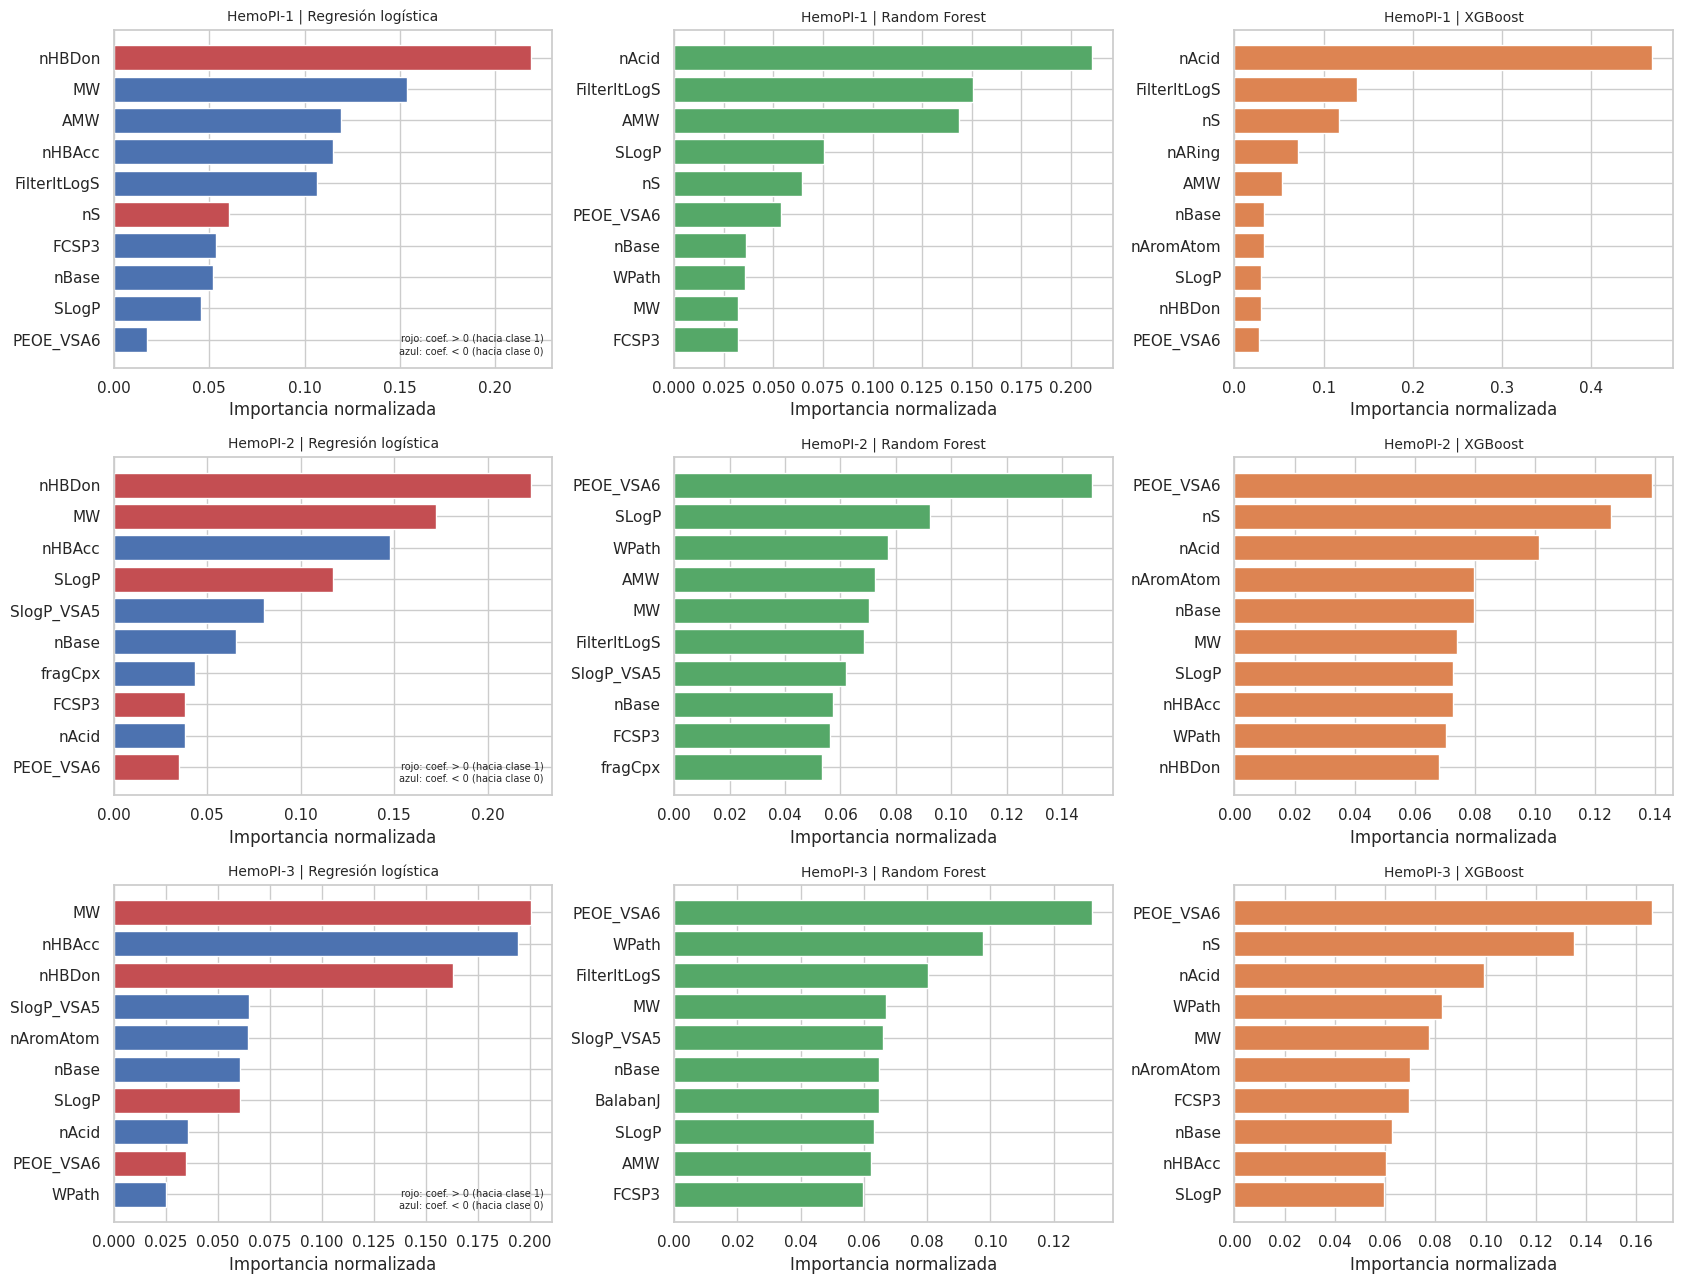

In [15]:
fig, axes = plt.subplots(len(DATASETS), len(MODELOS), figsize=(17, 13))
for i, ds in enumerate(DATASETS):
    for j, mod in enumerate(MODELOS):
        ax = axes[i, j]
        top = imps[(ds, mod)].head(10).iloc[::-1]          # los 10 más importantes (invertido para barh)
        if mod == 'Regresión logística':
            colores = np.where(top['coef_estandarizado'] >= 0, '#C44E52', '#4C72B0')   # rojo: empuja hacia clase 1
        else:
            colores = COLOR[mod]
        ax.barh(top['descriptor'], top['importancia'], color=colores)
        ax.set_title(f'{ds} | {mod}', fontsize=10)
        ax.set_xlabel('Importancia normalizada')
        if mod == 'Regresión logística':
            ax.text(0.98, 0.04, 'rojo: coef. > 0 (hacia clase 1)\nazul: coef. < 0 (hacia clase 0)',
                    transform=ax.transAxes, ha='right', fontsize=7)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/top10_importancias.png', dpi=200, bbox_inches='tight')
plt.show()

In [16]:
# Tablas top 10 con el significado fisicoquímico (útil para redactar la interpretación)
for ds in DATASETS:
    for mod in MODELOS:
        print(f'\n=== {ds} | {mod} ===')
        display(imps[(ds, mod)].head(10).round(3))


=== HemoPI-1 | Regresión logística ===


,descriptor,importancia,coef_estandarizado,significado
0,nHBDon,0.219,9.353,donadores de puentes de H
1,MW,0.154,-6.565,masa molecular
2,AMW,0.119,-5.083,masa atómica media
3,nHBAcc,0.115,-4.910,aceptores de puentes de H
4,FilterItLogS,0.107,-4.550,solubilidad acuosa estimada (logS)
5,nS,0.060,2.571,átomos de azufre
6,FCSP3,0.054,-2.296,fracción de carbonos sp3
7,nBase,0.052,-2.214,grupos básicos
8,SLogP,0.046,-1.960,lipofilia estimada (logP de Crippen)
9,PEOE_VSA6,0.017,-0.738,superficie por rango de carga parcial PEOE (6)



=== HemoPI-1 | Random Forest ===


,descriptor,importancia,coef_estandarizado,significado
0,nAcid,0.211,NaN,grupos ácidos
1,FilterItLogS,0.151,NaN,solubilidad acuosa estimada (logS)
2,AMW,0.144,NaN,masa atómica media
3,SLogP,0.076,NaN,lipofilia estimada (logP de Crippen)
4,nS,0.064,NaN,átomos de azufre
5,PEOE_VSA6,0.054,NaN,superficie por rango de carga parcial PEOE (6)
6,nBase,0.036,NaN,grupos básicos
7,WPath,0.036,NaN,índice de Wiener (tamaño y compactación)
8,MW,0.032,NaN,masa molecular
9,FCSP3,0.032,NaN,fracción de carbonos sp3



=== HemoPI-1 | XGBoost ===


,descriptor,importancia,coef_estandarizado,significado
0,nAcid,0.468,NaN,grupos ácidos
1,FilterItLogS,0.138,NaN,solubilidad acuosa estimada (logS)
2,nS,0.117,NaN,átomos de azufre
3,nARing,0.071,NaN,anillos aromáticos
4,AMW,0.053,NaN,masa atómica media
5,nBase,0.033,NaN,grupos básicos
6,nAromAtom,0.033,NaN,átomos aromáticos
7,SLogP,0.030,NaN,lipofilia estimada (logP de Crippen)
8,nHBDon,0.030,NaN,donadores de puentes de H
9,PEOE_VSA6,0.027,NaN,superficie por rango de carga parcial PEOE (6)


... (8 outputs left out)


=== HemoPI-3 | Random Forest ===


,descriptor,importancia,coef_estandarizado,significado
0,PEOE_VSA6,0.132,NaN,superficie por rango de carga parcial PEOE (6)
1,WPath,0.098,NaN,índice de Wiener (tamaño y compactación)
2,FilterItLogS,0.080,NaN,solubilidad acuosa estimada (logS)
3,MW,0.067,NaN,masa molecular
4,SlogP_VSA5,0.066,NaN,superficie por intervalo de contribución a log...
5,nBase,0.065,NaN,grupos básicos
6,BalabanJ,0.065,NaN,índice de Balaban (ramificación y forma)
7,SLogP,0.063,NaN,lipofilia estimada (logP de Crippen)
8,AMW,0.062,NaN,masa atómica media
9,FCSP3,0.060,NaN,fracción de carbonos sp3



=== HemoPI-3 | XGBoost ===


,descriptor,importancia,coef_estandarizado,significado
0,PEOE_VSA6,0.166,NaN,superficie por rango de carga parcial PEOE (6)
1,nS,0.135,NaN,átomos de azufre
2,nAcid,0.099,NaN,grupos ácidos
3,WPath,0.083,NaN,índice de Wiener (tamaño y compactación)
4,MW,0.078,NaN,masa molecular
5,nAromAtom,0.070,NaN,átomos aromáticos
6,FCSP3,0.070,NaN,fracción de carbonos sp3
7,nBase,0.063,NaN,grupos básicos
8,nHBAcc,0.060,NaN,aceptores de puentes de H
9,SLogP,0.060,NaN,lipofilia estimada (logP de Crippen)


### 7.2 Descriptores consistentes entre modelos

Un descriptor que aparece entre los más importantes en los tres modelos es una señal más fiable que uno que solo destaca en uno. La tabla muestra la importancia de cada descriptor en cada modelo (vacío = no seleccionado) y en cuántos modelos fue seleccionado.

In [17]:
consenso = {}
for ds in DATASETS:
    t = pd.concat({mod: imps[(ds, mod)].set_index('descriptor')['importancia'] for mod in MODELOS}, axis=1)
    t['n_modelos'] = t[MODELOS].notna().sum(axis=1)
    t['importancia_media'] = t[MODELOS].mean(axis=1)
    t['significado'] = t.index.map(DESCRIPCION)
    consenso[ds] = t.sort_values(['n_modelos', 'importancia_media'], ascending=False)
    consenso[ds].round(3).to_csv(f'{TAB_DIR}/consenso_descriptores_{ds}.csv')
    print(f'\n=== {ds} ===')
    display(consenso[ds].round(3))


=== HemoPI-1 ===


,Regresión logística,Random Forest,XGBoost,n_modelos,importancia_media,significado
descriptor,,,,,,
nAcid,0.014,0.211,0.468,3,0.231,grupos ácidos
FilterItLogS,0.107,0.151,0.138,3,0.132,solubilidad acuosa estimada (logS)
AMW,0.119,0.144,0.053,3,0.105,masa atómica media
nHBDon,0.219,0.027,0.030,3,0.092,donadores de puentes de H
nS,0.060,0.064,0.117,3,0.081,átomos de azufre
SLogP,0.046,0.076,0.030,3,0.051,lipofilia estimada (logP de Crippen)
nBase,0.052,0.036,0.033,3,0.040,grupos básicos
nARing,0.016,0.028,0.071,3,0.038,anillos aromáticos
PEOE_VSA6,0.017,0.054,0.027,3,0.033,superficie por rango de carga parcial PEOE (6)



=== HemoPI-2 ===


,Regresión logística,Random Forest,XGBoost,n_modelos,importancia_media,significado
descriptor,,,,,,
nHBDon,0.223,0.044,0.068,3,0.112,donadores de puentes de H
PEOE_VSA6,0.035,0.151,0.139,3,0.108,superficie por rango de carga parcial PEOE (6)
MW,0.172,0.070,0.074,3,0.106,masa molecular
SLogP,0.117,0.092,0.073,3,0.094,lipofilia estimada (logP de Crippen)
nHBAcc,0.147,0.046,0.073,3,0.089,aceptores de puentes de H
nBase,0.065,0.057,0.080,3,0.067,grupos básicos
nAcid,0.038,0.024,0.101,3,0.054,grupos ácidos
AMW,0.006,0.072,0.065,3,0.048,masa atómica media
nS,NaN,0.029,0.125,2,0.077,átomos de azufre



=== HemoPI-3 ===


,Regresión logística,Random Forest,XGBoost,n_modelos,importancia_media,significado
descriptor,,,,,,
MW,0.201,0.067,0.078,3,0.115,masa molecular
PEOE_VSA6,0.035,0.132,0.166,3,0.111,superficie por rango de carga parcial PEOE (6)
nHBAcc,0.194,0.042,0.060,3,0.099,aceptores de puentes de H
WPath,0.025,0.098,0.083,3,0.068,índice de Wiener (tamaño y compactación)
SlogP_VSA5,0.065,0.066,0.059,3,0.063,superficie por intervalo de contribución a log...
nBase,0.061,0.065,0.063,3,0.063,grupos básicos
SLogP,0.061,0.063,0.060,3,0.061,lipofilia estimada (logP de Crippen)
nAromAtom,0.065,0.036,0.070,3,0.057,átomos aromáticos
nS,0.006,0.025,0.135,3,0.055,átomos de azufre


## 8. Correlaciones y redundancias entre los descriptores seleccionados

Matriz de correlación de Pearson (datos de entrenamiento) entre los descriptores que **al menos un modelo** seleccionó. La Parte 2 ya eliminó los pares con |r| > 0,9, por lo que aquí se revisan las correlaciones **moderadas** (|r| ≥ 0,7), que pueden repartir la importancia entre descriptores parecidos y volver inestable la interpretación.

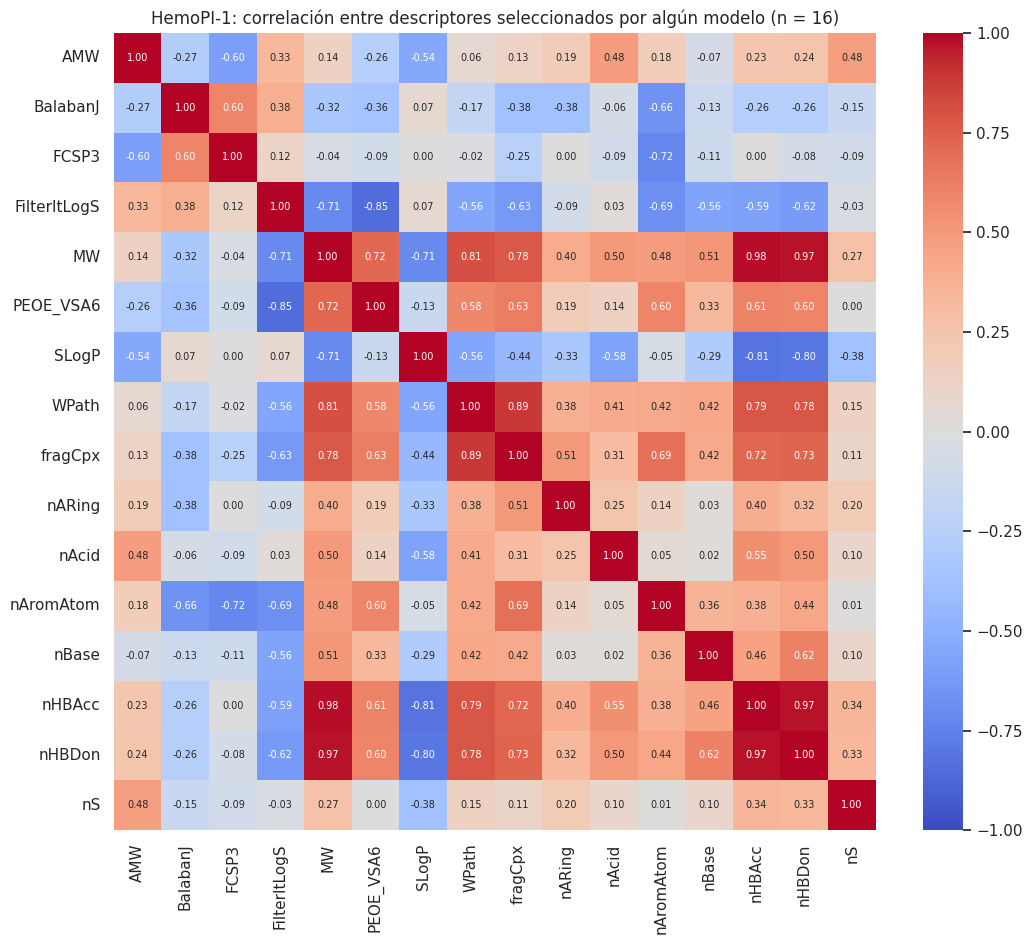

HemoPI-1: 17 pares con |r| >= 0,7 | |r| máxima = 0.981


,descriptor_1,descriptor_2,r
0,MW,nHBAcc,0.981
1,nHBAcc,nHBDon,0.975
2,MW,nHBDon,0.970
3,WPath,fragCpx,0.887
4,FilterItLogS,PEOE_VSA6,-0.846
5,SLogP,nHBAcc,-0.815
6,MW,WPath,0.812
7,SLogP,nHBDon,-0.797
8,WPath,nHBAcc,0.787
9,WPath,nHBDon,0.785


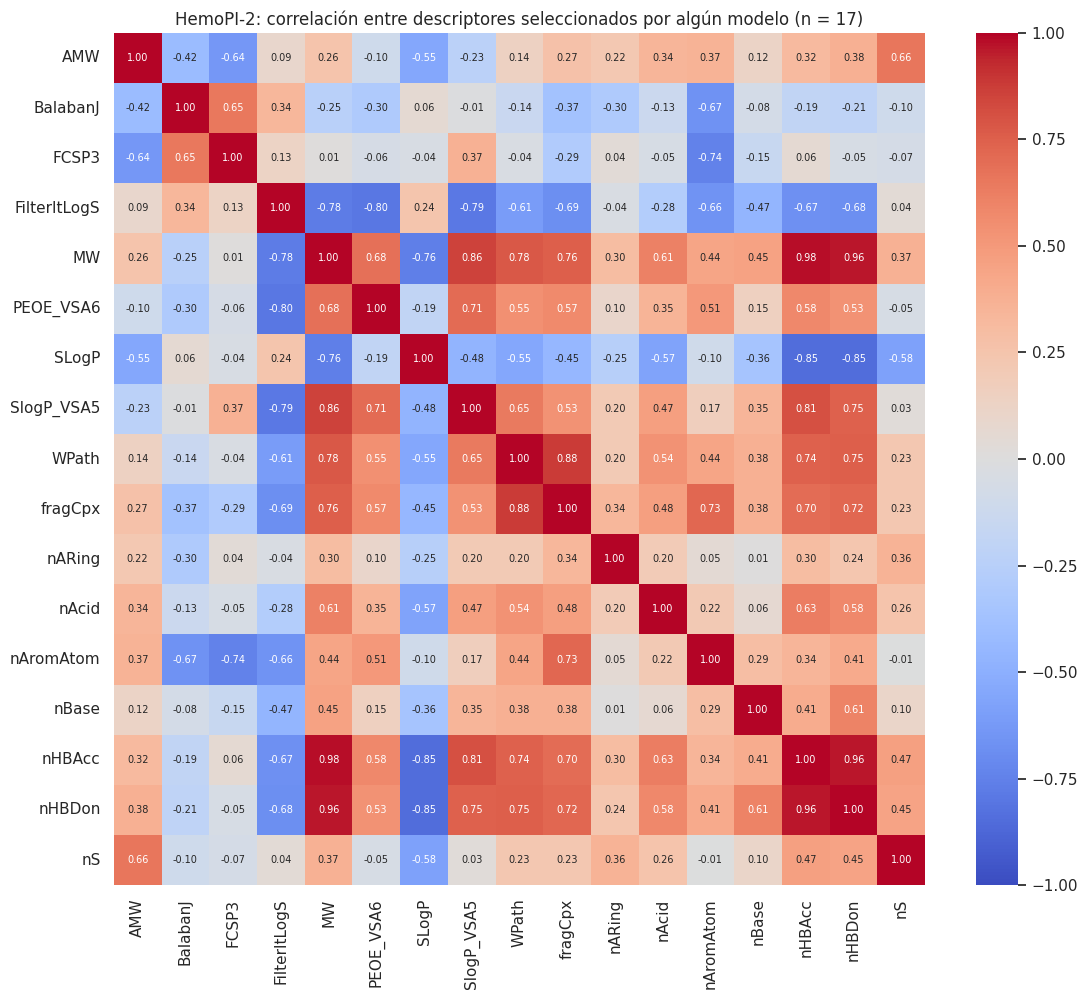

HemoPI-2: 21 pares con |r| >= 0,7 | |r| máxima = 0.983


,descriptor_1,descriptor_2,r
0,MW,nHBAcc,0.983
1,nHBAcc,nHBDon,0.964
2,MW,nHBDon,0.963
3,WPath,fragCpx,0.882
4,MW,SlogP_VSA5,0.855
5,SLogP,nHBAcc,-0.850
6,SLogP,nHBDon,-0.846
7,SlogP_VSA5,nHBAcc,0.811
8,FilterItLogS,PEOE_VSA6,-0.799
9,FilterItLogS,SlogP_VSA5,-0.790


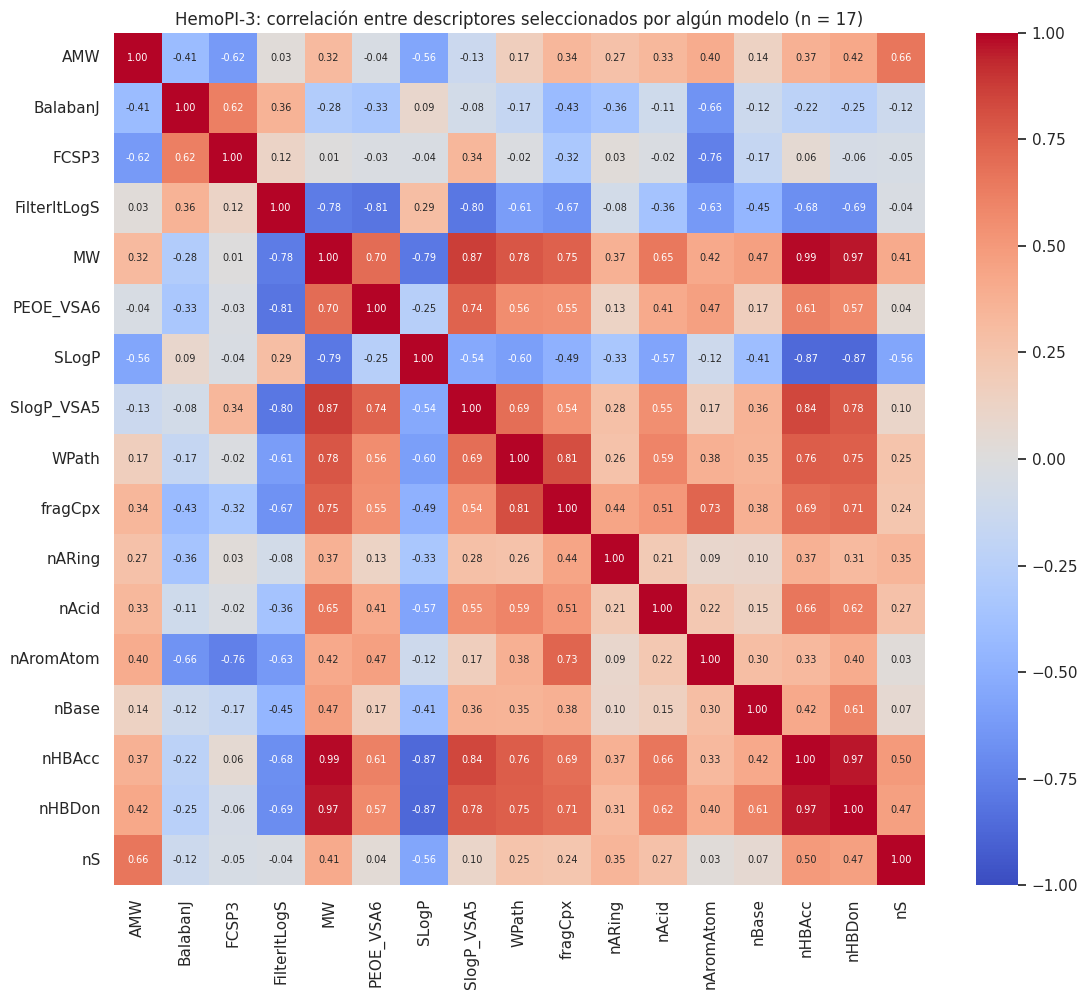

HemoPI-3: 22 pares con |r| >= 0,7 | |r| máxima = 0.985


,descriptor_1,descriptor_2,r
0,MW,nHBAcc,0.985
1,MW,nHBDon,0.968
2,nHBAcc,nHBDon,0.967
3,MW,SlogP_VSA5,0.874
4,SLogP,nHBDon,-0.869
5,SLogP,nHBAcc,-0.865
6,SlogP_VSA5,nHBAcc,0.838
7,WPath,fragCpx,0.814
8,FilterItLogS,PEOE_VSA6,-0.806
9,FilterItLogS,SlogP_VSA5,-0.799


In [18]:
pares_altos = {}
for ds in DATASETS:
    union = sorted(set().union(*[set(imps[(ds, m)]['descriptor']) for m in MODELOS]))
    corr = datos[ds]['X_tr'][union].corr(method='pearson')

    plt.figure(figsize=(1 + 0.62 * len(union), 0.8 + 0.55 * len(union)))
    sns.heatmap(corr, annot=True, fmt='.2f', annot_kws={'size': 7}, cmap='coolwarm', center=0, vmin=-1, vmax=1)
    plt.title(f'{ds}: correlación entre descriptores seleccionados por algún modelo (n = {len(union)})')
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/correlacion_{ds}.png', dpi=200, bbox_inches='tight')
    plt.show()

    # Pares con correlación moderada o alta
    tri = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    pares = tri.stack().rename('r').reset_index()
    pares.columns = ['descriptor_1', 'descriptor_2', 'r']
    pares = pares[pares['r'].abs() >= 0.7].sort_values('r', key=np.abs, ascending=False).reset_index(drop=True)
    pares_altos[ds] = pares
    pares.round(3).to_csv(f'{TAB_DIR}/pares_correlacionados_{ds}.csv', index=False)
    print(f'{ds}: {len(pares)} pares con |r| >= 0,7 | |r| máxima = {tri.abs().max().max():.3f}')
    display(pares.round(3))

## 9. Guardado de resultados

Se guardan, en `Act1_PSU/resultados_modelos/`:
- `modelos/`: modelo final de cada dataset y algoritmo (`.joblib`, un `Pipeline` completo que puede predecir directamente) y los `GridSearchCV` completos.
- `tablas/`: métricas, mejores hiperparámetros, importancias y correlaciones.
- `figuras/`: curvas ROC, top 10 de importancias y matrices de correlación.

In [19]:
# Modelo final = mejor Pipeline reajustado con todo el entrenamiento (selección + clasificador)
for (ds, mod), gs in gridsearch.items():
    joblib.dump(gs.best_estimator_, f'{MOD_DIR}/{ds}_{SLUG[mod]}_modelo_final.joblib')

# Hiperparámetros ganadores en formato legible
params = {f'{ds} | {mod}': {k: (v if isinstance(v, (int, float, str, type(None))) else str(v))
                            for k, v in gs.best_params_.items()}
          for (ds, mod), gs in gridsearch.items()}
with open(f'{TAB_DIR}/mejores_hiperparametros.json', 'w') as f:
    json.dump(params, f, indent=2, ensure_ascii=False)

print('Contenido de', RES_DIR)
for sub in ('modelos', 'tablas', 'figuras'):
    print(f'  {sub}/:', len(os.listdir(f'{RES_DIR}/{sub}')), 'archivos')

# Ejemplo de uso de un modelo guardado: predecir la validación externa de HemoPI-1 con XGBoost
m = joblib.load(f'{MOD_DIR}/HemoPI-1_xgboost_modelo_final.joblib')
print('AUC externa HemoPI-1 XGBoost (modelo recargado):',
      round(roc_auc_score(datos['HemoPI-1']['y_va'], m.predict_proba(datos['HemoPI-1']['X_va'])[:, 1]), 3))

Contenido de /content/drive/MyDrive/Act1_PSU/resultados_modelos
  modelos/: 18 archivos
  tablas/: 20 archivos
  figuras/: 5 archivos
AUC externa HemoPI-1 XGBoost (modelo recargado): 0.983


## 10. Cómo redactar la interpretación de los descriptores (guía)

Para cada dataset, con las tablas de la sección 7:
1. **Identifica los descriptores del top 10** que se repiten en los tres modelos (tabla de consistencia, sección 7.2).
2. **Dirección del efecto.** Usa el signo de los coeficientes de la regresión logística (rojo/azul en el gráfico). Los modelos de árboles solo indican cuánto contribuye cada descriptor, no la dirección.
3. **Significado fisicoquímico.** La columna `significado` indica qué mide cada descriptor (tamaño, lipofilia, carga, polaridad, aromaticidad, forma). Relaciona cada uno con una **hipótesis** de mecanismo (por ejemplo, cómo la hidrofobicidad o la carga podrían afectar la interacción de un péptido con la membrana del eritrocito) y **respáldala con literatura**. Aquí no se incluyen afirmaciones biológicas porque dependen de fuentes que debes citar.
4. **Redundancia.** Si dos descriptores importantes correlacionan (sección 8), indica que su importancia puede estar repartida y que no se pueden separar sus efectos.
5. **Causalidad.** Importancia no implica causalidad: son asociaciones estadísticas entre un descriptor calculado y la etiqueta.

## 11. Limitaciones del enfoque

- **Descriptores 2D:** calculados a partir del SMILES, no codifican el orden de la secuencia, la estructura secundaria ni la anfipaticidad. Son propiedades que suelen importar en la interacción péptido-membrana, y su ausencia limita el techo de desempeño.
- **Selección a criterio y filtrado previo:** de los 1613 descriptores de Mordred solo se calcularon 45 elegidos manualmente, y la Parte 2 conservó los que superaron el filtro de correlación. Descriptores relevantes que no estaban en la selección no pudieron participar.
- **Filtro de correlación voraz:** conserva el primer descriptor de cada grupo redundante, no el más informativo. Que un descriptor no aparezca como importante no significa que sea irrelevante, puede estar representado por otro.
- **Tamaño de muestra:** con unos cientos o pocos miles de péptidos, las métricas tienen incertidumbre (ver los intervalos bootstrap), y diferencias pequeñas entre modelos pueden no ser significativas.
- **Validación externa no completamente independiente:** es una partición aleatoria de la misma fuente de datos. Péptidos con secuencias muy similares pueden estar a ambos lados del corte, lo que infla el desempeño; no se controló la similitud de secuencia. Una validación realmente independiente requeriría péptidos de otra fuente o agrupados por homología.
- **Heterogeneidad de los datos:** los datos agregan mediciones de varias fuentes (verifica en el artículo), con posibles diferencias experimentales (tipo de eritrocito, concentración, tiempo de incubación) que se reflejan como ruido en las etiquetas.
- **Definición de las clases en HemoPI-2 y HemoPI-3:** deben interpretarse según la definición del repositorio (potencia hemolítica alta/baja según el artículo), no como hemolítico/no hemolítico.
- **Umbral fijo 0,5 y sin calibración:** las métricas de clase dependen del umbral; no se evaluó la calibración de las probabilidades.
- **Una sola partición externa:** el resultado puede cambiar con otra partición. Los hiperparámetros se eligieron con los mismos pliegues con que se reporta la CV, así que el desempeño interno es algo optimista.
- **Importancia de variables:** la importancia de los modelos de árboles depende de las correlaciones entre descriptores y no tiene signo. Los coeficientes de la regresión logística son estables solo bajo regularización y escalado.
- **Dominio de aplicabilidad:** los modelos solo son fiables para péptidos parecidos a los de entrenamiento (longitud, composición, aminoácidos naturales).